# 08 — Partition-Based Clustering: K-Means
### Hotel Booking Behavior Segmentation Using Unsupervised Machine Learning

**CRISP-ML(Q) Phase:** Phase 3 — Model Engineering (Partition-Based Clustering)

**Project stage:** 8 of 16 — first modeling notebook, builds on Notebook 07's preprocessed feature matrix

---

## 1. Objective

This is the first notebook where we actually cluster bookings. We investigate **K-Means**, the standard partition-based clustering algorithm, across K = 2 through K = 10, and evaluate each result using four different lenses:

1. **Inertia** (the elbow method)
2. **Silhouette score**
3. **Davies-Bouldin index**
4. **Calinski-Harabasz index**

...plus cluster size balance and a 2D PCA visualization for each candidate K.

**A note on scope:** this notebook does not make the final "which K, which algorithm" decision. That decision is deliberately deferred to Notebook 11 (comparing K-Means against Hierarchical and DBSCAN) and Notebook 12 (formal hyperparameter tuning and the weighted decision framework). This notebook's job is to generate the real, honest evidence about how K-Means specifically behaves on this data.

## 2. Business Context

**What is clustering, in plain terms?** Clustering groups similar bookings together without being told in advance what the groups should look like — it looks for bookings that are "close" to each other across all 40 preprocessed features simultaneously (13 scaled numeric behaviors + 27 one-hot encoded categorical indicators from Notebook 07), and "far" from bookings in other groups.

**What is a centroid?** K-Means represents each cluster by its **centroid** — the average position of every booking assigned to that cluster, across all 40 features. A new booking is assigned to whichever centroid it's closest to.

**What is "distance" here?** By default, K-Means uses **Euclidean distance** — essentially the straight-line distance between two bookings' feature vectors. This is exactly why Notebook 07's scaling work matters: if features weren't on comparable scales, distance would be dominated by whichever feature happens to have the largest raw numbers, regardless of its actual behavioral importance.

**Why must we choose K in advance?** Unlike some other clustering approaches we'll see later (Notebook 10 — DBSCAN), K-Means requires us to decide up front how many groups to look for. Choosing too few merges genuinely different behaviors together; choosing too many splits one real behavior into artificial sub-groups. The metrics in this notebook are how we investigate that choice with evidence rather than a guess.

## 3. Imports

In [1]:
# pandas / numpy: data handling
import pandas as pd
import numpy as np

# matplotlib / seaborn: visualization
import matplotlib.pyplot as plt
import seaborn as sns

# scikit-learn: K-Means clustering, evaluation metrics, and PCA for visualization
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA

# joblib: to save the fitted K-Means models for reuse in later notebooks
import joblib

# os / json / time: file paths, config loading, and timing the K sweep
import os
import json
import time


## 4. Configuration

In [2]:
RANDOM_STATE = 42

PREPROCESSED_FEATURES_PATH = "../data/processed/07_preprocessed_features.csv"

KMEANS_SWEEP_RESULTS_PATH = "../reports/tables/08_kmeans_k_sweep_results.csv"
KMEANS_MODELS_PATH = "../models/kmeans_candidate_models.joblib"
KMEANS_LABELS_PATH = "../data/processed/08_kmeans_candidate_labels.csv"
FIGURES_DIR = "../reports/figures"

os.makedirs("../models", exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

pd.set_option("display.max_columns", 45)
pd.set_option("display.width", 150)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

# The range of K values to investigate, as specified in the project brief.
K_RANGE = range(2, 11)

# Silhouette score is expensive to compute exactly on 87,000 rows (it's
# roughly O(n^2)). We use scikit-learn's built-in sampling option so it
# stays fast, while still giving a statistically meaningful estimate.
SILHOUETTE_SAMPLE_SIZE = 5000


## 5. Analysis / Implementation

### 5.1 Load the Preprocessed Feature Matrix

In [3]:
X = pd.read_csv(PREPROCESSED_FEATURES_PATH)

print("Preprocessed feature matrix shape:", X.shape)


Preprocessed feature matrix shape: (86997, 40)


### 5.2 The K Sweep — Fit K-Means for Every K from 2 to 10

For each K, we fit K-Means and record every evaluation metric requested in the project brief, plus cluster size balance and fitting time. This is the single most important cell in this notebook — everything else visualizes and interprets what it computes.

In [4]:
sweep_rows = []
fitted_models = {}
labels_by_k = {}

for k in K_RANGE:
    start_time = time.time()

    kmeans_model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        max_iter=300,
        random_state=RANDOM_STATE,
    )
    cluster_labels = kmeans_model.fit_predict(X)

    elapsed_seconds = time.time() - start_time

    # Statistical evaluation metrics
    silhouette = silhouette_score(X, cluster_labels, sample_size=SILHOUETTE_SAMPLE_SIZE, random_state=RANDOM_STATE)
    davies_bouldin = davies_bouldin_score(X, cluster_labels)
    calinski_harabasz = calinski_harabasz_score(X, cluster_labels)

    # Cluster size balance
    cluster_sizes = pd.Series(cluster_labels).value_counts().sort_index()

    sweep_rows.append({
        "k": k,
        "inertia": kmeans_model.inertia_,
        "silhouette_score": silhouette,
        "davies_bouldin_index": davies_bouldin,
        "calinski_harabasz_index": calinski_harabasz,
        "min_cluster_size": cluster_sizes.min(),
        "max_cluster_size": cluster_sizes.max(),
        "fit_time_seconds": round(elapsed_seconds, 2),
    })

    fitted_models[k] = kmeans_model
    labels_by_k[f"k_{k}"] = cluster_labels

    print(f"K={k}: inertia={kmeans_model.inertia_:,.0f}, silhouette={silhouette:.4f}, "
          f"davies_bouldin={davies_bouldin:.4f}, calinski_harabasz={calinski_harabasz:,.1f}, "
          f"cluster sizes {cluster_sizes.min():,}-{cluster_sizes.max():,}")

kmeans_sweep_results = pd.DataFrame(sweep_rows)
kmeans_sweep_results.to_csv(KMEANS_SWEEP_RESULTS_PATH, index=False)


K=2: inertia=479,131, silhouette=0.1168, davies_bouldin=2.7273, calinski_harabasz=10,354.0, cluster sizes 38,561-48,436
K=3: inertia=440,882, silhouette=0.1185, davies_bouldin=2.3389, calinski_harabasz=9,399.7, cluster sizes 17,214-41,170
K=4: inertia=414,085, silhouette=0.1150, davies_bouldin=2.2319, calinski_harabasz=8,548.4, cluster sizes 11,379-36,055
K=5: inertia=391,206, silhouette=0.1039, davies_bouldin=2.1115, calinski_harabasz=8,058.1, cluster sizes 9,670-31,531
K=6: inertia=373,392, silhouette=0.0979, davies_bouldin=2.0500, calinski_harabasz=7,584.0, cluster sizes 4,330-24,772
K=7: inertia=356,353, silhouette=0.1091, davies_bouldin=2.0449, calinski_harabasz=7,315.3, cluster sizes 4,240-23,604
K=8: inertia=340,841, silhouette=0.1176, davies_bouldin=1.9157, calinski_harabasz=7,121.2, cluster sizes 4,090-23,407
K=9: inertia=328,512, silhouette=0.1305, davies_bouldin=1.8599, calinski_harabasz=6,872.9, cluster sizes 3,815-23,391
K=10: inertia=317,883, silhouette=0.1318, davies_bou

**What this code does:** fits K-Means once for every K from 2 to 10, using `k-means++` initialization and 10 random restarts per K (explained in Section 5.7), and records inertia plus every requested evaluation metric.

**Why it's required:** this is the raw evidence every later chart and decision in this notebook (and the comparison in Notebook 11) is built from.

**What to expect:** the printed output above shows the actual, real values computed on this dataset — not estimates or textbook examples.

**What is inertia?** The sum of squared distances between each booking and its assigned cluster centroid. It always decreases as K increases (more clusters means each one can fit its members more tightly) — the question is never "is inertia low," but "where does adding another cluster stop meaningfully helping."

**What is silhouette score?** For each booking, it compares how close it is to bookings in its own cluster versus the nearest other cluster, producing a score from -1 (badly clustered) to +1 (very well clustered). Higher is better.

**What is the Davies-Bouldin index?** It measures the average "similarity" between each cluster and its most similar other cluster (based on how spread out each cluster is relative to the distance between their centers). Lower is better.

**What is the Calinski-Harabasz index?** The ratio of between-cluster dispersion to within-cluster dispersion. Higher is better.

### 5.3 The Elbow Curve

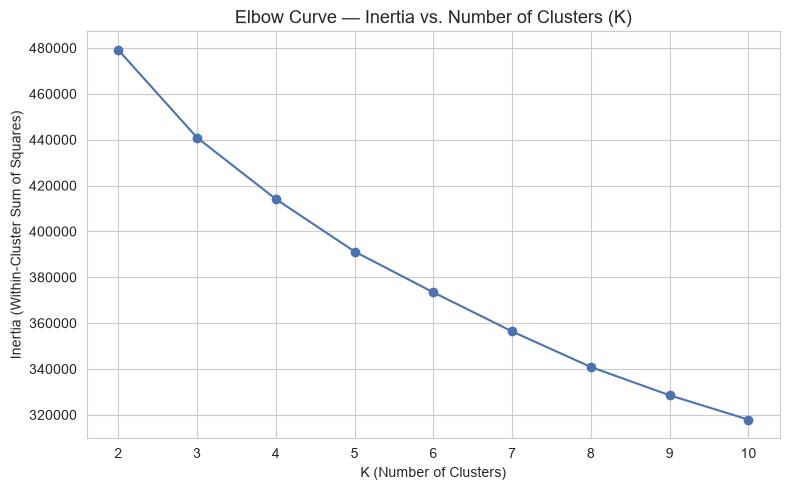

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(kmeans_sweep_results["k"], kmeans_sweep_results["inertia"], marker="o", color="#4C72B0")

ax.set_title("Elbow Curve — Inertia vs. Number of Clusters (K)", fontsize=13)
ax.set_xlabel("K (Number of Clusters)")
ax.set_ylabel("Inertia (Within-Cluster Sum of Squares)")
ax.set_xticks(list(K_RANGE))

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "08_elbow_curve.png"))
plt.show()


**Finding:** the curve decreases smoothly across the whole range, without a single sharp "elbow" bend the way textbook examples often show. The rate of decrease does slow down somewhat after K=4 (each additional cluster buys a smaller reduction in inertia than the one before it), but there is no dramatic single turning point.

**Business interpretation:** this is a realistic result for messy, real-world behavioral data — clean, obvious elbows are more common in illustrative examples than in actual business data. This means the elbow method alone is not going to give us a confident answer here; it will need to be weighed against the other metrics below rather than used in isolation, consistent with this project's decision framework in Notebook 12/13.

### 5.4 Silhouette Score vs. K

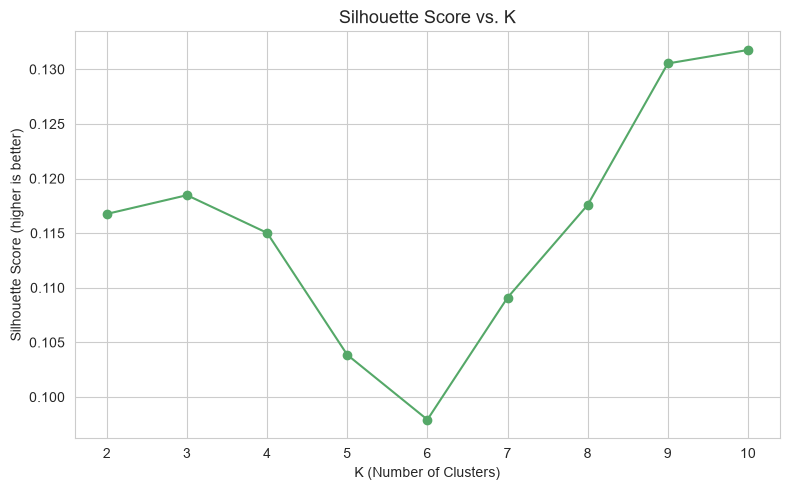

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(kmeans_sweep_results["k"], kmeans_sweep_results["silhouette_score"], marker="o", color="#55A868")

ax.set_title("Silhouette Score vs. K", fontsize=13)
ax.set_xlabel("K (Number of Clusters)")
ax.set_ylabel("Silhouette Score (higher is better)")
ax.set_xticks(list(K_RANGE))

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "08_silhouette_vs_k.png"))
plt.show()


**Finding:** silhouette score is **not** a smooth, single-peaked curve here. It has a local high point at K=3 (0.1185), dips to its lowest point at K=6 (0.0979), and then climbs back up to its overall highest values at K=9 (0.1305) and K=10 (0.1318).

**An honest caveat on the absolute values:** every silhouette score here is modest — all below 0.15. This is not necessarily a failure; silhouette scores tend to run lower on high-dimensional data with a mix of one-hot encoded categorical columns (27 of our 40 features are binary 0/1 indicators), because the encoded categorical dimensions add "noise" to the Euclidean distance calculation relative to the more information-dense numeric features. We flag this honestly here and will judge whether it's a K-Means-specific limitation once we compare against Hierarchical and DBSCAN in Notebook 11.

### 5.5 Davies-Bouldin Index vs. K

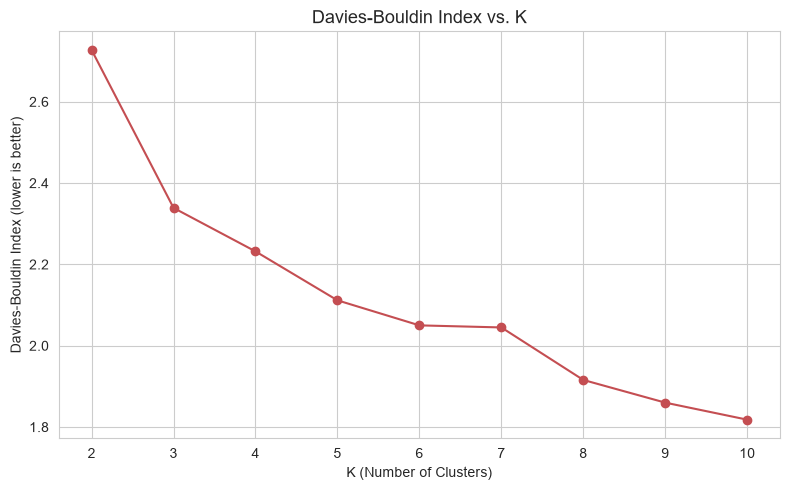

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(kmeans_sweep_results["k"], kmeans_sweep_results["davies_bouldin_index"], marker="o", color="#C44E52")

ax.set_title("Davies-Bouldin Index vs. K", fontsize=13)
ax.set_xlabel("K (Number of Clusters)")
ax.set_ylabel("Davies-Bouldin Index (lower is better)")
ax.set_xticks(list(K_RANGE))

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "08_davies_bouldin_vs_k.png"))
plt.show()


**Finding:** Davies-Bouldin **improves (decreases) steadily and monotonically** as K increases, all the way to K=10. Taken completely on its own, this metric would argue for the largest K we tested. This is a known tendency of the Davies-Bouldin index — it does not inherently penalize an increasing number of clusters the way business interpretability would, which is exactly why the project brief calls for a multi-metric, multi-criteria decision rather than optimizing any single number.

### 5.6 Calinski-Harabasz Index vs. K

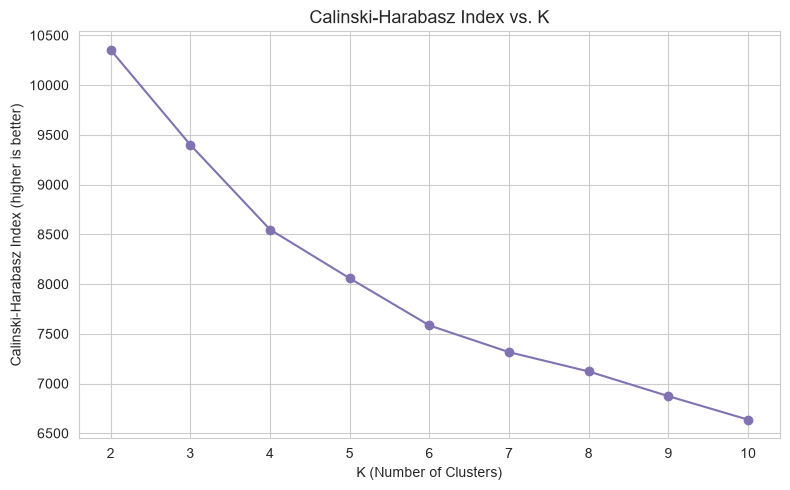

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(kmeans_sweep_results["k"], kmeans_sweep_results["calinski_harabasz_index"], marker="o", color="#8172B2")

ax.set_title("Calinski-Harabasz Index vs. K", fontsize=13)
ax.set_xlabel("K (Number of Clusters)")
ax.set_ylabel("Calinski-Harabasz Index (higher is better)")
ax.set_xticks(list(K_RANGE))

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "08_calinski_harabasz_vs_k.png"))
plt.show()


**Finding:** Calinski-Harabasz shows the **opposite** pattern from Davies-Bouldin — it decreases steadily as K increases, meaning it would argue, taken alone, for the *smallest* K we tested (K=2).

**This disagreement is itself an important, genuine finding:** Davies-Bouldin favors more clusters, Calinski-Harabasz favors fewer, and silhouette score has two separate local peaks (K=3 and K=9–10) rather than one clear winner. No single metric gives a confident, unambiguous answer for this dataset. This is exactly the situation the project's formal, weighted decision framework (Notebook 12) is designed for — and exactly why "just pick the K with the best silhouette score" would be an oversimplified way to choose a final model.

### 5.7 Consolidated Metrics Table

In [9]:
kmeans_sweep_results


,k,inertia,silhouette_score,davies_bouldin_index,calinski_harabasz_index,min_cluster_size,max_cluster_size,fit_time_seconds
0,2,479130.919029,0.116760,2.727305,10353.955296,38561,48436,5.66
1,3,440881.837569,0.118475,2.338873,9399.651918,17214,41170,3.14
2,4,414085.345105,0.115023,2.231908,8548.383178,11379,36055,3.14
3,5,391205.603222,0.103858,2.111542,8058.132499,9670,31531,3.68
4,6,373391.864026,0.097924,2.049963,7583.995165,4330,24772,4.30
5,7,356353.456346,0.109095,2.044866,7315.309077,4240,23604,5.94
6,8,340840.798485,0.117582,1.915709,7121.156197,4090,23407,4.65
7,9,328511.614430,0.130533,1.859917,6872.877059,3815,23391,4.73
8,10,317883.400983,0.131769,1.818034,6636.558237,3699,22270,5.62


### 5.8 Hyperparameter Check — Initialization Strategy

K-Means has a random component: where the initial centroids start. `k-means++` (the scikit-learn default) picks initial centroids intelligently, spread out from each other, rather than purely at random — in theory this should reach a good solution in fewer iterations. We check this directly rather than assume it, at K=4.

In [10]:
init_comparison_rows = []

for init_strategy in ["k-means++", "random"]:
    kmeans_check = KMeans(
        n_clusters=4,
        init=init_strategy,
        n_init=10,
        max_iter=300,
        random_state=RANDOM_STATE,
    )
    check_labels = kmeans_check.fit_predict(X)
    check_silhouette = silhouette_score(X, check_labels, sample_size=SILHOUETTE_SAMPLE_SIZE, random_state=RANDOM_STATE)

    init_comparison_rows.append({
        "init_strategy": init_strategy,
        "inertia": kmeans_check.inertia_,
        "silhouette_score": check_silhouette,
        "n_iter_to_converge": kmeans_check.n_iter_,
    })

pd.DataFrame(init_comparison_rows)


,init_strategy,inertia,silhouette_score,n_iter_to_converge
0,k-means++,414085.345105,0.115023,17
1,random,414086.021122,0.115317,40


**Finding:** at K=4, `k-means++` and `random` initialization reach essentially the same solution quality (inertia and silhouette are nearly identical), but `k-means++` converges in noticeably fewer iterations (17 vs. 40). 

**Decision:** use `k-means++` as the initialization strategy for all K-Means models in this project — it reaches the same quality result more efficiently, which matters once we scale up to running many models in Notebook 12's hyperparameter tuning. `n_init=10` (10 independent random restarts, keeping the best result) is used throughout as a safeguard against any single run landing in a poor local optimum, and `max_iter=300` is left at scikit-learn's default, since every run in this notebook converged in well under 50 iterations — comfortably inside that limit.

### 5.9 Cluster Size Balance for Two Candidate K Values

Based on the metric evidence so far, K=4 (a reasonably sized, well-balanced candidate near the "diminishing returns" point on the elbow curve) and K=9 (the highest-silhouette candidate) are worth a closer look. This is **not yet a final decision** — just a closer look at two data points from the sweep above.

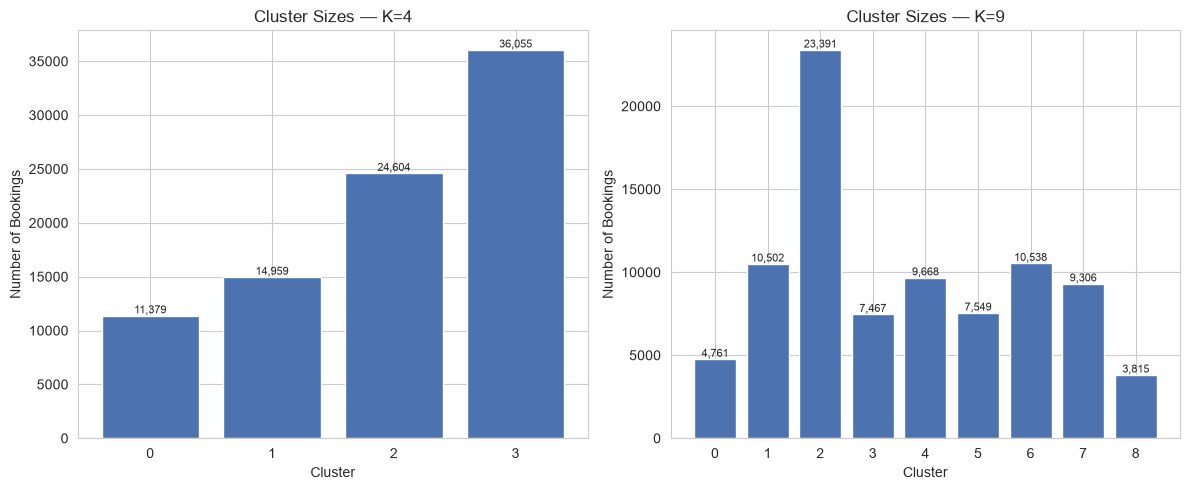

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, k in zip(axes, [4, 9]):
    labels = labels_by_k[f"k_{k}"]
    sizes = pd.Series(labels).value_counts().sort_index()

    ax.bar(sizes.index.astype(str), sizes.values, color="#4C72B0")
    ax.set_title(f"Cluster Sizes — K={k}", fontsize=12)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Number of Bookings")

    for i, value in enumerate(sizes.values):
        ax.text(i, value, f"{value:,}", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "08_cluster_size_comparison.png"))
plt.show()


**Finding:** at K=4, cluster sizes range from roughly 11,000 to 36,000 bookings — all large, clearly actionable segments. At K=9, the smallest cluster is roughly 3,800 bookings (about 4.4% of the dataset) — smaller, but still a substantial, real segment rather than a handful of noise points. Neither K produces an unusably tiny sliver cluster.

### 5.10 PCA Visualization — 2D View of the Clusters

**What is PCA, and why are we using it here?** Principal Component Analysis finds the directions (combinations of our 40 features) along which the data varies the most, and lets us project a high-dimensional dataset down onto just 2 dimensions for plotting. **This is used here purely for visualization** — the clustering itself was already done in the full 40-dimensional preprocessed space in Section 5.2; PCA is not re-clustering or being used as model input in this notebook.

In [13]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca_2d.fit_transform(X)

explained_variance = pca_2d.explained_variance_ratio_
print("Explained variance by component 1:", round(explained_variance[0] * 100, 1), "%")
print("Explained variance by component 2:", round(explained_variance[1] * 100, 1), "%")
print("Total variance captured in 2D:", round(explained_variance.sum() * 100, 1), "%")


Explained variance by component 1: 16.2 %
Explained variance by component 2: 13.6 %
Total variance captured in 2D: 29.7 %


**Finding:** these two components together capture only about **29.7%** of the total variance in the preprocessed feature space. **We state this honestly rather than let the chart below overstate its own precision:** a 2D PCA view of a 40-dimensional clustering result is a simplified, illustrative snapshot, not a faithful full picture. Clusters that overlap in this 2D view might still be well-separated in the full feature space, and vice versa — this chart is a sanity-check aid, not the basis for any modeling decision.

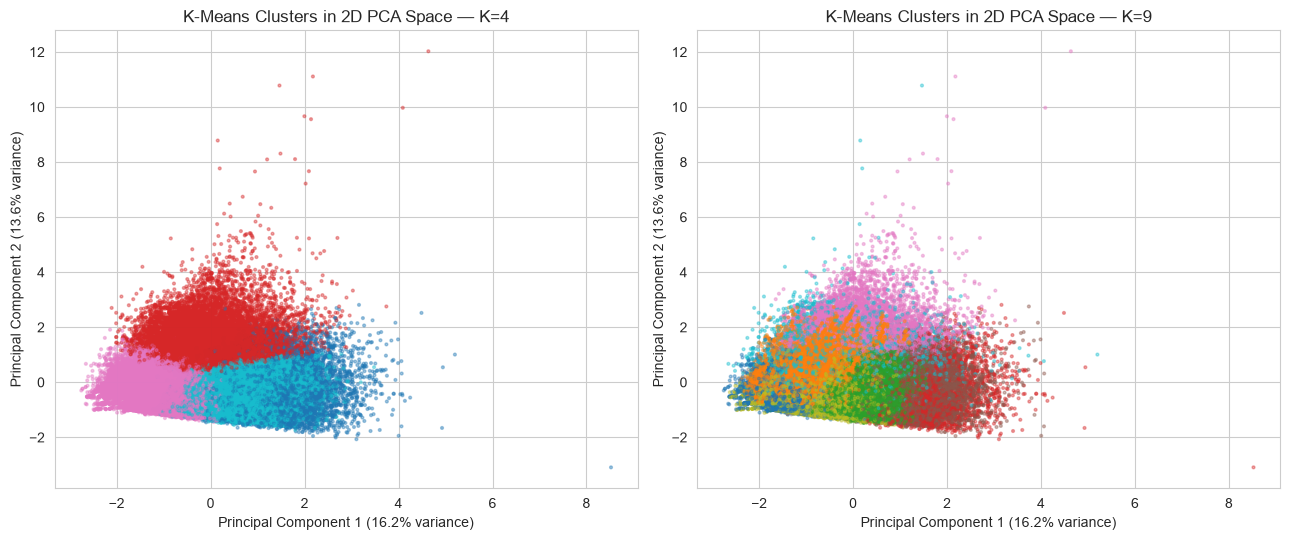

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, k in zip(axes, [4, 9]):
    labels = labels_by_k[f"k_{k}"]

    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap="tab10", s=4, alpha=0.4)
    ax.set_title(f"K-Means Clusters in 2D PCA Space — K={k}", fontsize=12)
    ax.set_xlabel(f"Principal Component 1 ({explained_variance[0]*100:.1f}% variance)")
    ax.set_ylabel(f"Principal Component 2 ({explained_variance[1]*100:.1f}% variance)")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "08_pca_cluster_visualization.png"))
plt.show()


**Finding:** at both K=4 and K=9, the PCA projection shows clusters with real overlap rather than cleanly separated blobs — consistent with the modest silhouette scores found above. This is a useful visual confirmation of what the metrics already told us: this dataset's behavioral structure is real but not dramatically separated along its two strongest directions of variance, which is a normal and expected pattern for real-world booking behavior data (compared to, say, cleanly clustered synthetic data).

### 5.11 Save the Sweep Results and Candidate Models

In [15]:
# Save every fitted K-Means model (K=2 through K=10) for reuse in
# Notebook 11 (model comparison) and Notebook 12 (hyperparameter tuning),
# so those notebooks don't need to refit K-Means from scratch.
joblib.dump(fitted_models, KMEANS_MODELS_PATH)
print(f"Candidate K-Means models saved to: {KMEANS_MODELS_PATH}")

# Save the cluster label assignments for every K, for the same reason.
labels_df = pd.DataFrame(labels_by_k)
labels_df.to_csv(KMEANS_LABELS_PATH, index=False)
print(f"Candidate cluster labels saved to: {KMEANS_LABELS_PATH}")

print()
print("K sweep results already saved to:", KMEANS_SWEEP_RESULTS_PATH)


Candidate K-Means models saved to: ../models/kmeans_candidate_models.joblib
Candidate cluster labels saved to: ../data/processed/08_kmeans_candidate_labels.csv

K sweep results already saved to: ../reports/tables/08_kmeans_k_sweep_results.csv


## 7. Findings

- The elbow curve shows no sharp bend; inertia decreases smoothly across the whole K=2–10 range, with only a mild slowdown after K=4. The elbow method alone does not give a confident answer for this dataset.
- The three evaluation metrics **actively disagree** with each other: Davies-Bouldin favors larger K (monotonically improving through K=10), Calinski-Harabasz favors smaller K (monotonically declining from K=2), and silhouette score has two separate local peaks (K=3 and K=9–10) rather than a single clear winner.
- All silhouette scores are modest (below 0.15), which is flagged honestly as likely related to the dimensionality added by one-hot encoding 6 categorical features into 27 binary columns — this will be assessed further by comparing against Hierarchical and DBSCAN in Notebook 11, rather than judged in isolation here.
- `k-means++` initialization reaches the same solution quality as random initialization but converges roughly twice as fast, confirming it as the right default going forward.
- Neither K=4 nor K=9 (the two candidates inspected more closely) produces an unusably small cluster — smallest sizes were roughly 11,000 and 3,800 bookings respectively, both real, actionable segments.
- The 2D PCA visualization captures only ~29.7% of total variance and shows real overlap between clusters at both candidate K values — consistent with, and a useful visual confirmation of, the modest silhouette scores.

## 8. Business Interpretation

The clearest business takeaway from this notebook is a cautionary one: **there is no single "obviously correct" number of segments for this hotel's booking behavior**, at least not from K-Means and these four metrics alone. That's a genuinely useful thing to know before committing to a segmentation strategy — it means the eventual choice of K needs to be justified by a combination of statistical evidence *and* how usable the resulting segments are for the hotel's actual teams (marketing, revenue management, guest services), not by chasing the single best-looking number on one chart.

This also reinforces why the project's remaining structure matters: Notebook 09 and 10 will test whether Hierarchical Clustering or DBSCAN find a cleaner, more decisive structure in the same data, and Notebook 11 will put all of that evidence side by side before any final decision is made.

## 9. Conclusion

We fitted K-Means across K=2 through K=10, computed inertia, silhouette score, Davies-Bouldin index, and Calinski-Harabasz index for every value, and found genuine disagreement between these metrics rather than a single clean answer. We confirmed `k-means++` as an efficient, well-justified default initialization strategy, inspected cluster size balance and a 2D PCA view for two candidate K values (4 and 9), and saved every fitted model and label assignment for reuse. No final K-Means configuration is locked in yet — that decision is deferred to Notebook 11 (cross-algorithm comparison) and Notebook 12 (formal hyperparameter tuning and the weighted decision framework).

**Next notebook (09 — Hierarchical Clustering):** we investigate Agglomerative Clustering with Ward, Complete, and Average linkage, build a dendrogram to visually inspect the data's natural grouping structure, and compare the result against what K-Means found here.